# Catastrophic forgetting on MNIST

A companion to Lecture 14

Marcel Turcotte  
2026-10-27

A network can learn a new task while losing the ability to solve an
earlier one. This notebook trains a small MLP first on MNIST digits
**0–4**, then on **5–9**. We measure both capabilities and compare
training on new data alone with replay of a small memory of old training
examples.

This extends Lecture 14’s discussion of training challenges. The model
has one fixed output layer with **ten logits** throughout; digit labels
retain their original values. At evaluation, all ten classes compete.
The experiment is a simple form of **class-incremental learning**, not
an evaluation that tells the model which five classes to choose from.
See <a href="https://arxiv.org/abs/1904.07734" class="external"
data-icon="true">van de Ven and Tolias (2019)</a>.

## Data and a reproducible training budget

We use MNIST’s official training/test separation. For a quick
experiment, each digit contributes 1,000 training images and 200
validation images from the official training partition. The official
test images are not used for choosing settings. The first run downloads
MNIST through Keras if it is not already cached.

The seeds fix the initialization and sampling settings. Exact results
can still vary with the backend and hardware; interpret the measured
forgetting and retention in the executed run rather than expecting
identical percentages on every system.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import keras

SEED = 42
EPOCHS = 6
STEPS_PER_EPOCH = 40
BATCH_SIZE = 128
LEARNING_RATE = 0.1

keras.utils.set_random_seed(SEED)
(images, labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
data_rng = np.random.default_rng(SEED)
train_indices, validation_indices = [], []
for digit in range(10):
    indices = data_rng.permutation(np.flatnonzero(labels == digit))
    train_indices.extend(indices[:1000])
    validation_indices.extend(indices[1000:1200])

train_images, train_labels = images[train_indices], labels[train_indices]
validation_images = images[validation_indices]
validation_labels = labels[validation_indices]
train_a = (train_images[train_labels < 5], train_labels[train_labels < 5])
train_b = (train_images[train_labels >= 5], train_labels[train_labels >= 5])
validation_a = (validation_images[validation_labels < 5], validation_labels[validation_labels < 5])
validation_b = (validation_images[validation_labels >= 5], validation_labels[validation_labels >= 5])

## One model, ten possible classes

The hidden layer uses ReLU and the output is linear.
`SparseCategoricalCrossentropy(from_logits=True)` receives the logits
directly and accepts integer digit labels. Softmax would convert those
logits to probabilities; `argmax` gives the same predicted class before
or after softmax.

SGD uses a constant learning rate with no momentum or regularization.
This keeps the comparison focused on the training data supplied during
the second phase.

In [3]:
def compile_model(model):
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=LEARNING_RATE),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True))

def make_model():
    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28)),
        keras.layers.Rescaling(1/255),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
        keras.layers.Dense(10)
    ])
    compile_model(model)
    return model

def predicted_classes(model, x):
    logits = keras.ops.convert_to_numpy(model(x, training=False))
    return logits.argmax(axis=1)

def validation_accuracy(model):
    return [np.mean(predicted_classes(model, x) == y)
            for x, y in (validation_a, validation_b)]

## The same training loop, with or without memory

Every phase has the same number of parameter updates and the same batch
size. Sampling with replacement makes that update budget explicit.
Without memory, each batch contains new-task examples only. With memory,
half of each batch comes from the new task and half from the stored old
examples. Replay therefore changes the data mixture within the fixed
budget.

The returned history records validation accuracy for both groups before
training and after each epoch. `train_on_batch` performs the forward
pass, gradient computation, and SGD update; the NumPy code only
constructs the batches.

In [4]:
def train_phase(model, training_data, seed, memory=None):
    rng = np.random.default_rng(seed)
    x, y = training_data
    history = [validation_accuracy(model)]
    new_count = BATCH_SIZE if memory is None else BATCH_SIZE // 2
    for epoch in range(EPOCHS):
        for _ in range(STEPS_PER_EPOCH):
            indices = rng.integers(len(y), size=new_count)
            xb, yb = x[indices], y[indices]
            if memory is not None:
                old_x, old_y = memory
                old_indices = rng.integers(len(old_y), size=BATCH_SIZE-new_count)
                xb = np.concatenate([xb, old_x[old_indices]])
                yb = np.concatenate([yb, old_y[old_indices]])
            model.train_on_batch(xb, yb)
        history.append(validation_accuracy(model))
    return np.asarray(history)

## Phase A: learn digits 0–4

In [5]:
sequential_model = make_model()
history_a = train_phase(sequential_model, train_a, seed=101)
weights_after_a = [weight.copy() for weight in sequential_model.get_weights()]
test_predictions_after_a = predicted_classes(sequential_model, test_images)
print('Validation accuracy after A:')
print(f'  digits 0–4: {history_a[-1, 0]:.1%}')
print(f'  digits 5–9: {history_a[-1, 1]:.1%}')

Validation accuracy after A:
  digits 0–4: 95.6%
  digits 5–9: 0.0%

Poor performance on digits 5–9 at this point is expected: they have not
been training targets. The reference for forgetting is the model’s
performance on digits 0–4 **after learning A**.

## Phase B: new data only versus replay

The sequential branch continues from its learned parameters. The replay
branch starts from an identical copy of those parameters. Both branches
use a fresh SGD optimizer with the same constant learning rate;
recompiling the sequential branch does not reinitialize its model
weights.

The memory stores twenty training images per old class, for one hundred
images in total. No validation or test image is placed in memory. The
same stage-B update count is used in both branches.

In [6]:
memory_rng = np.random.default_rng(202)
memory_indices = np.concatenate([
    memory_rng.choice(np.flatnonzero(train_a[1] == digit), size=20, replace=False)
    for digit in range(5)
])
memory = (train_a[0][memory_indices], train_a[1][memory_indices])

replay_model = make_model()
replay_model.set_weights(weights_after_a)
compile_model(sequential_model)
history_b = train_phase(sequential_model, train_b, seed=303)
history_replay = train_phase(replay_model, train_b, seed=303, memory=memory)

## Follow both capabilities

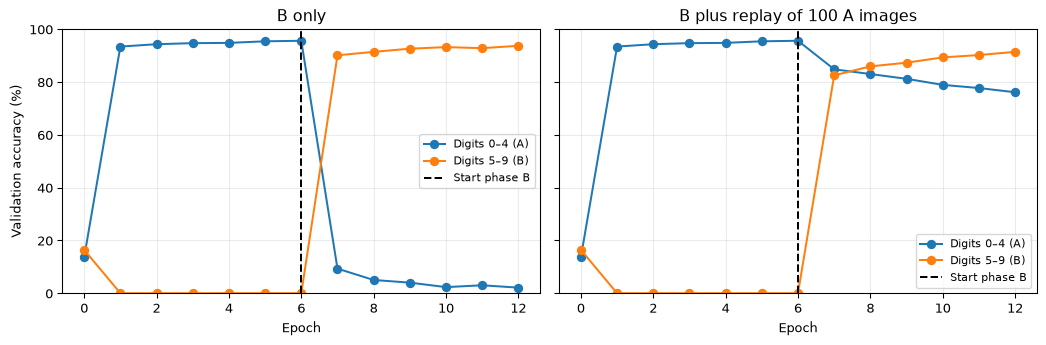

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
for ax, continuation, title in zip(axes, (history_b, history_replay),
                                  ('B only', 'B plus replay of 100 A images')):
    history = np.vstack([history_a, continuation[1:]])
    epochs = np.arange(len(history))
    ax.plot(epochs, 100*history[:, 0], 'o-', label='Digits 0–4 (A)')
    ax.plot(epochs, 100*history[:, 1], 'o-', label='Digits 5–9 (B)')
    ax.axvline(EPOCHS, color='black', linestyle='--', label='Start phase B')
    ax.set(title=title, xlabel='Epoch', ylim=(0, 100), xticks=np.arange(0, 2*EPOCHS+1, 2))
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Validation accuracy (%)')
fig.tight_layout()
fig.savefig('catastrophic_forgetting_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()

The two panels share the same phase-A history. Read the second phase in
two directions: does the model learn B, and how much of A does it
retain? The validation curves describe this fixed experiment; they are
not used here to select hyperparameters or stopping times.

Replay reduces forgetting in this experiment but does not eliminate it.
Some of the fixed phase-B update budget is devoted to A, so both
retention and new-task performance should be considered when comparing
the branches.

## Stage-end measurements on the official test set

Report the groups separately: aggregate accuracy can hide a large loss
of an earlier capability. All ten output classes remain available for
every prediction.

In [8]:
test_predictions_sequential = predicted_classes(sequential_model, test_images)
test_predictions_replay = predicted_classes(replay_model, test_images)
mask_a = test_labels < 5

def group_accuracies(predictions):
    correct = predictions == test_labels
    return np.array([correct[mask_a].mean(), correct[~mask_a].mean(), correct.mean()])

test_results = {
    'After A': group_accuracies(test_predictions_after_a),
    'After B only': group_accuracies(test_predictions_sequential),
    'After B with replay': group_accuracies(test_predictions_replay)
}
print(f"{'Checkpoint':<22} {'A (0–4)':>10} {'B (5–9)':>10} {'All digits':>12}")
for name, values in test_results.items():
    print(f'{name:<22}' + ''.join(f'{100*value:>10.1f}%' for value in values))
for name in ('After B only', 'After B with replay'):
    forgetting_pp = 100*(test_results['After A'][0]-test_results[name][0])
    print(f'A accuracy drop, {name}: {forgetting_pp:.1f} percentage points')

Checkpoint                A (0–4)    B (5–9)   All digits
After A                     97.1%       0.0%      49.9%
After B only                 2.3%      93.9%      46.8%
After B with replay         79.8%      91.4%      85.4%
A accuracy drop, After B only: 94.8 percentage points
A accuracy drop, After B with replay: 17.3 percentage points

These measurements compare predeclared checkpoints. The phase-A test
predictions were recorded before phase-B training and are not recomputed
using later parameters.

## The same images, different predictions

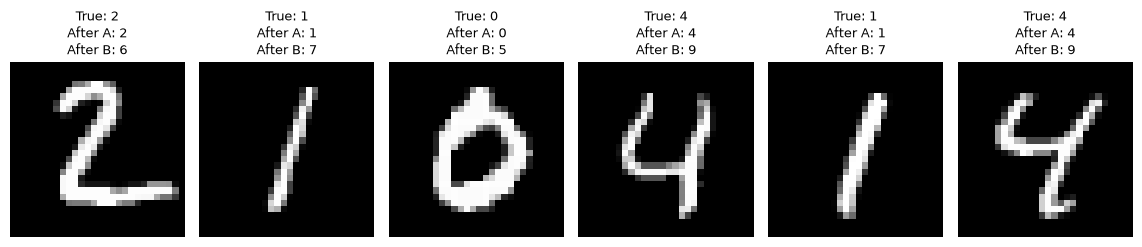

In [9]:
forgotten = np.flatnonzero(mask_a & (test_predictions_after_a == test_labels)
                           & (test_predictions_sequential != test_labels))[:6]
if len(forgotten):
    fig, axes = plt.subplots(1, len(forgotten), figsize=(2*len(forgotten), 2.6), squeeze=False)
    for ax, index in zip(axes[0], forgotten):
        ax.imshow(test_images[index], cmap='gray')
        ax.set_title(f'True: {test_labels[index]}\nAfter A: {test_predictions_after_a[index]}\nAfter B: {test_predictions_sequential[index]}', fontsize=10)
        ax.axis('off')
    fig.tight_layout()
    plt.show()
else:
    print('No previously correct A test images became incorrect in this run.')

The inputs and their labels did not change. The parameters changed
during further training. In this disjoint-class example, the decline can
include a strong bias toward recent classes as well as changes in shared
features; it does not establish that every useful old representation has
been erased.

## What does this imply for deployed models?

Prediction with a trained model normally leaves its weights fixed.
Learning requires an explicit update process. Catastrophic forgetting
can occur during online learning or during periodic batch fine-tuning
when new updates do not protect earlier behavior.

Production neural networks can learn online;
<a href="https://arxiv.org/abs/2209.07663" class="external"
data-icon="true">Monolith</a> is a real-time recommendation example. The
lesson is to design and evaluate updates carefully, not that online
learning is impossible. <a
href="https://developers.google.com/machine-learning/crash-course/production-ml-systems/static-vs-dynamic-training"
class="external" data-icon="true">Google’s production-ML discussion</a>
distinguishes static and dynamic training.

Replay explicitly reintroduces an objective on earlier data. Ordinary
zero-centered L2 penalizes large weights; it does not explicitly
preserve previously learned predictions. Methods such as
<a href="https://arxiv.org/abs/1612.00796" class="external"
data-icon="true">elastic weight consolidation</a> use other mechanisms
to protect earlier learning. No continual-learning method is implemented
or claimed to be universally best here.

For reflection: why can B accuracy rise while A accuracy falls? Why is
reporting only the mean accuracy insufficient? What changes when old
examples occupy part of the fixed stage-B update budget?

[Return to Lecture 14](index.qmd).